# Fusing GEDI with a raster: ESA BIOMASS forest height

This demo aggregates quality-filtered GEDI rh_98 onto the pixels of a raster, then compares the two. The same pattern works for any single-band raster and any GEDI variable, and it runs in under a minute on a 16GB node for a scene this size.

The example raster is one ESA BIOMASS L2A forest height scene (`FP_FH__L2A`) over inland Gabon, posted at ~93 m. **To use your own raster, change `RASTER_PATH` below; everything else adapts to its grid and CRS.**

If you haven't used the tiled GEDI database before, you may want to start with `quickstart.ipynb`.

In [3]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import rioxarray
from gtiler.database import ducky

# Attach to the tiled GEDI database
con = ducky.init_duckdb(temp_dir="/tmp/duckdb")
ducky.attach_ducklake(
    con=con,
    bucket="maap-ops-workspace",
    prefix="shared/ameliah/tiled_gedi_v3",
    name="gedi_dl",
)

## Inputs

`RASTER_PATH` can be any single-band, north-up raster that rasterio can read: a local file or an `s3://` path, in any CRS, with its nodata value set.

In [1]:
RASTER_PATH = "s3://maap-ops-workspace/shared/ameliah/demos/bio_fp_fh__l2a_20260306t172140_20260318t172209_t_g01_m02_c___t011_f157_i_fh.tiff"
RASTER_LABEL = "BIOMASS forest height (m)"

EPSG:4326 (0.0008335113525390625, -0.0008333921432495117) (1637, 1014)


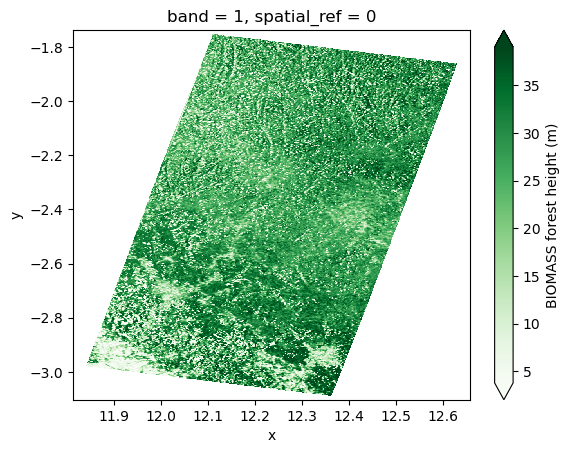

In [4]:
raster = rioxarray.open_rasterio(RASTER_PATH, masked=True).squeeze()
print(raster.rio.crs, raster.rio.resolution(), raster.shape)
raster.plot.imshow(robust=True, cmap="Greens", cbar_kwargs={"label": RASTER_LABEL})

## Processing
### 1. Assign each GEDI shot to a raster pixel

We will push all the processing into DuckDB, trying to load only our final aggregated dataset into memory.

In the first step, we create a DuckDB table view (`shots`) with the columns and rows we need for the aggregation. We:

SELECT

- The scientific column of interest (RH 98, which is read as `rh_l2a[99]` in SQL)
- The raster pixel coordinates of each shot (`x_idx`, `y_idx`) [1]

FROM

- The GEDI shots that fall within the raster extent (`gedi_bbox`)

WHERE

- The footprints pass quality filtering

[1] <small> A pixel's column and row come straight from the raster's affine transform: `x_idx = floor((x - x0) / dx)` and `y_idx = floor((y0 - y) / dy)`, where `(x0, y0)` is the top-left corner. For a lon/lat raster, `x` and `y` are the shot's lon/lat. For a projected raster, DuckDB first transforms each shot into the raster's CRS. </small>

In [5]:
# Get the raster transformation
t = raster.rio.transform()
x0, dx, y0, dy = t.c, t.a, t.f, -t.e
height, width = raster.shape
lon_min, lat_min, lon_max, lat_max = raster.rio.transform_bounds("EPSG:4326")

# Check whether the raster is in a non-standard CRS,
# in which case we need to transform the GEDI data into the raster CRS
if raster.rio.crs.is_geographic:
    point = "ST_Point(lon_lowestmode, lat_lowestmode)"
    pixel_m = dy * 111_320
else:
    point = f"ST_Transform(ST_Point(lon_lowestmode, lat_lowestmode), 'EPSG:4326', '{raster.rio.crs.to_wkt()}', always_xy := true)"
    pixel_m = dy

# This SQL query creates a DuckDB table (shots)
# that has our filtered data with all the columns we need for aggregation
# It is not loaded into memory.
con.sql(f"""--sql
    CREATE OR REPLACE TEMP TABLE shots AS
    SELECT
        floor((ST_X(p) - {x0}) / {dx})::INT AS x_idx,
        floor(({y0} - ST_Y(p)) / {dy})::INT AS y_idx,
        rh98
    FROM (
        SELECT 
            {point} AS p, 
            rh_l2a[99] AS rh98
        FROM gedi_bbox({lon_min}, {lat_min}, {lon_max}, {lat_max})
        WHERE
            -- add your own quality filters here 
            l2a_quality_flag_rel3_l2a = 1
            AND degrade_flag_l2a = 0
            AND sensitivity_l2a >= 0.95
    )
    WHERE x_idx BETWEEN 0 AND {width - 1} AND y_idx BETWEEN 0 AND {height - 1}
""")

# Check how many footprints we are working with
con.sql("SELECT count(*) AS n_shots, mean(rh98) AS mean_rh98 FROM shots")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌─────────┬────────────────────┐
│ n_shots │     mean_rh98      │
│  int64  │       double       │
├─────────┼────────────────────┤
│   77000 │ 29.164058960744313 │
└─────────┴────────────────────┘

### 2. Aggregate per pixel

In the second step, we aggregate GEDI footprints per pixel using `GROUP BY` in SQL. We have finished the DuckDB processing, so at the end we are ready to call `.df()` to pull the data into memory.

At ~93 m most pixels hold only one or two GEDI shots, so 2×2 blocks (~186 m) give steadier means. They are also closer to BIOMASS's ~200 m effective resolution.

You can adjust the block size using the `BLOCK` variable.

In [ ]:
BLOCK = 2

df = con.sql(f"""--sql
        SELECT
            x_idx // {BLOCK} AS x_idx,
            y_idx // {BLOCK} AS y_idx,
            -- choose the statistics for aggregation
            count(*) AS n_shots,
            avg(rh98) AS rh98_mean,
            stddev_samp(rh98) AS rh98_std
        FROM shots
        GROUP BY 1, 2
    """).df()

# Coarsen the raster as well to match the block size
if BLOCK == 1:
    grid = raster
else:
    with warnings.catch_warnings():  # blocks outside the raster's footprint are all-NaN
        warnings.simplefilter("ignore", RuntimeWarning)
        grid = raster.coarsen(x=BLOCK, y=BLOCK, boundary="pad").mean()

# Get the values of the (coarsened) raster
# for each x_idx, y_idx pixel value
df["raster"] = grid.values[df.y_idx, df.x_idx]

df.n_shots.value_counts().sort_index()

n_shots
1     13920
2      8582
3      6378
4      4928
5       443
6       337
7       246
8       118
9        14
10        3
11        1
Name: count, dtype: int64

## Plotting results

`to_raster` writes a column of the per-pixel table back onto a raster grid, so it can be mapped or saved as a GeoTIFF next to the input.

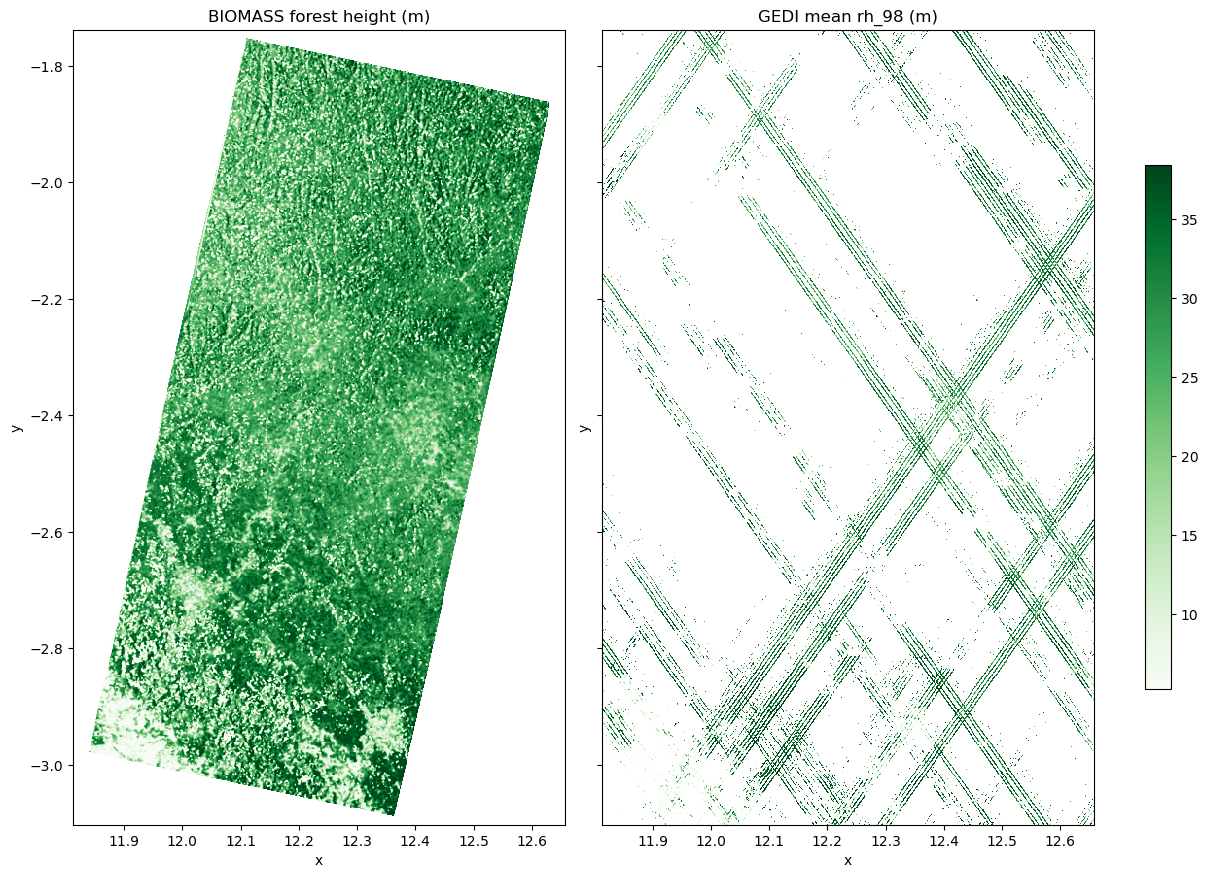

In [10]:
def to_raster(df, grid, column="rh98_mean"):
    out = np.full(grid.shape, np.nan, dtype="float32")
    out[df.y_idx, df.x_idx] = df[column]
    return grid.copy(data=out)

gedi_raster = to_raster(df, grid)
gedi_raster.rio.to_raster(f"/tmp/gedi_rh98_mean_{BLOCK}x{BLOCK}.tif")

vmin, vmax = np.nanpercentile(grid.values, [2, 98])
fig, axes = plt.subplots(1, 2, figsize=(12, 9), sharex=True, sharey=True, layout="constrained")
for ax, da, title in [(axes[0], grid, RASTER_LABEL), (axes[1], gedi_raster, "GEDI mean rh_98 (m)")]:
    im = da.plot.imshow(ax=ax, vmin=vmin, vmax=vmax, cmap="Greens", add_colorbar=False)
    ax.set_title(title)
    ax.set_aspect("equal")
fig.colorbar(im, ax=axes, shrink=0.6)

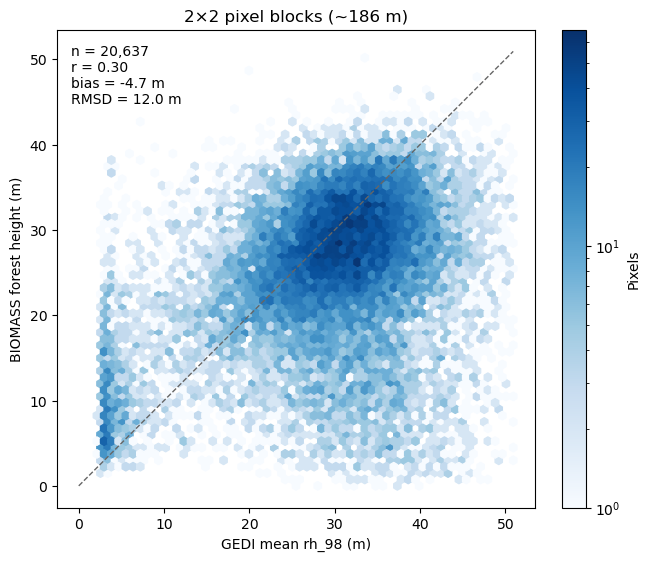

In [11]:
d = df.dropna(subset=["raster", "rh98_mean"])
hi = np.nanpercentile(np.concatenate([d.rh98_mean, d.raster]), 99.5)

r = np.corrcoef(d.rh98_mean, d.raster)[0, 1]
bias = (d.raster - d.rh98_mean).mean()
rmsd = np.sqrt(((d.raster - d.rh98_mean) ** 2).mean())

fig, ax = plt.subplots(figsize=(6.5, 5.5), layout="constrained")
hb = ax.hexbin(d.rh98_mean, d.raster, gridsize=60, extent=(0, hi, 0, hi), mincnt=1, bins="log", cmap="Blues")
ax.plot([0, hi], [0, hi], color="0.4", lw=1, ls="--")
ax.text(0.03, 0.97, f"n = {len(d):,}\nr = {r:.2f}\nbias = {bias:.1f} m\nRMSD = {rmsd:.1f} m",
        transform=ax.transAxes, va="top")
ax.set_title(f"{BLOCK}×{BLOCK} pixel blocks (~{BLOCK * pixel_m:.0f} m)")
ax.set_xlabel("GEDI mean rh_98 (m)")
ax.set_ylabel(RASTER_LABEL)
ax.set_aspect("equal")
fig.colorbar(hb, ax=ax, label="Pixels")

## Scaling up

- **Time** is dominated by the GEDI scan in the `shots` cell, roughly 5 s per 1°×1° tile the raster overlaps. A ~100-tile mosaic takes about 9 minutes.
- **Memory**: DuckDB is capped at 8GB by `init_duckdb` and spills to `temp_dir` beyond that. The raster itself is held in memory, so a scene or tile at a time fits easily, but a continental mosaic may not. To cover many scenes, loop this notebook's steps over them, and save each scene's per-pixel table (e.g. `gedi_2x2.to_parquet(...)`) instead of keeping them all.
- **Shots per pixel** depend on pixel size. Report `n_shots` with any per-pixel mean, and consider requiring a minimum.

## About the example raster

The scene is from the ESA MAAP catalogue (`https://catalog.maap.eo.esa.int/catalogue/`): collection `BiomassLevel2a`, product type `FP_FH__L2A`, item `BIO_FP_FH__L2A_20260306T172140_20260318T172209_T_G01_M02_C___T011_F157_02_DUFRC9`. BIOMASS downloads need an ESA MAAP token; see the [MAAP BIOMASS data access guide](https://docs.maap-project.org/en/hub/science/ESA_BIOMASS/ESA_BIOMASS_Data_Access.html).